In [1]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq, minimize_scalar
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator
from astropy.time import Time
from typing import Union, List
from scipy.signal import find_peaks

import frb_functions

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as ticker

In [2]:
def gaus(x, a, x0, sigma, d):
    return a * np.exp(-((x - x0) ** 2) / (2 * sigma ** 2)) + d

# Define sum of two Gaussians
def flipped_gaus(x, a, x0, sigma, d):
    return -a * np.exp(-((x - x0) ** 2) / (2 * sigma ** 2)) + d

In [3]:
def load_burst(DM, burst_name):

    ###################################
    burst = your.Your(burst_name)

    header_dict = frb_functions.your_header_to_dict(burst)
    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] 
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = header_dict["fmin"]
    fmax = header_dict["fmax"]
    extent_b = [tmin, tmax, fmin, fmax]

    offset = 0.119 #seconds -bin = int(0.119/16e-6) 
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(f"the extent of the data is: {extent_b}")
    
    #time increasing, freq decreasing
    print("loading in the data")
    full_pol_data = frb_functions.get_data(burst, nstart=0, nsamp=nbins, npoln=4)

    sides_bandpass = 'right' 
    scale_bandpass = 3
    #get coherence products    
    aa = full_pol_data["AA"]
    aa_norm = frb_functions.correct_bandpass(aa, sides=sides_bandpass, scale=scale_bandpass)
    
    bb = full_pol_data["BB"]
    bb_norm = frb_functions.correct_bandpass(bb, sides=sides_bandpass, scale=scale_bandpass)  
    
    #make stokesi 
    d = aa_norm + bb_norm
    d = frb_functions.correct_bandpass(d, sides=sides_bandpass, scale=scale_bandpass)
    
    freqs = header_dict["freqs"] # in Mhz
       
    dm_dedisp = DM
    print(f"de-dispersing to {dm_dedisp} pc/cc")
    stokes_i = frb_functions.dedisperse(d,dm_dedisp,freqs,tsamp)

    print(f"Masking channels")
    mask_arr = frb_functions.extract_numbers_pazi(input_string='paz -z "49 45 46 30 28 15 16 127 126 125 123 122 121 102 103 93" -e pazi B01-NRT.fil.ar',\
                                                 total_channels=128, map_channels=True)
    print(mask_arr)
    stokes_i = frb_functions.mask_array(array=stokes_i, bad_chan_idx=mask_arr)

    print(f"Correcting for the bandpass")
    stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)

    downsamp_t = 1
    downsamp_f = 1
    print(f"downsample factors are: time:{downsamp_t} and freq:{downsamp_f}")
    if downsamp_f > 1 or downsamp_t > 1:
        print(f"running downsampling and correcting bandpass")
        stokes_i = frb_functions.downsample(stokes_i, freqf=downsamp_f, timef=downsamp_t)
        tsamp = tsamp * downsamp_t
        fsamp = fsamp * downsamp_f
        stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)
        downsamp_flag = True
    else:
        downsamp_flag = False

    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=stokes_i.shape[1])

    prof = np.ma.mean(stokes_i,axis=0)
    stokes_i_normprof = frb_functions.normalize_1d(prof, sides=sides_bandpass, scale=scale_bandpass)

    new_quantiles = np.nanpercentile(stokes_i, (1.0, 99.99))
    
    return stokes_i, stokes_i_normprof, x_grid, new_quantiles, extent_b

the extent of the data is: [-119.0, 2881.0, 1228.0, 1740.0]
loading in the data
de-dispersing to 464.863 pc/cc
Masking channels
[ 78  82  81  97  99 112 111   0   1   2   4   5   6  25  24  34]
Correcting for the bandpass
downsample factors are: time:1 and freq:1


/usr/local/anaconda/lib/python3.11/site-packages/numpy/lib/function_base.py:4737: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


the extent of the data is: [-119.0, 2881.0, 1228.0, 1740.0]
loading in the data
de-dispersing to 465.534 pc/cc
Masking channels
[ 78  82  81  97  99 112 111   0   1   2   4   5   6  25  24  34]
Correcting for the bandpass
downsample factors are: time:1 and freq:1


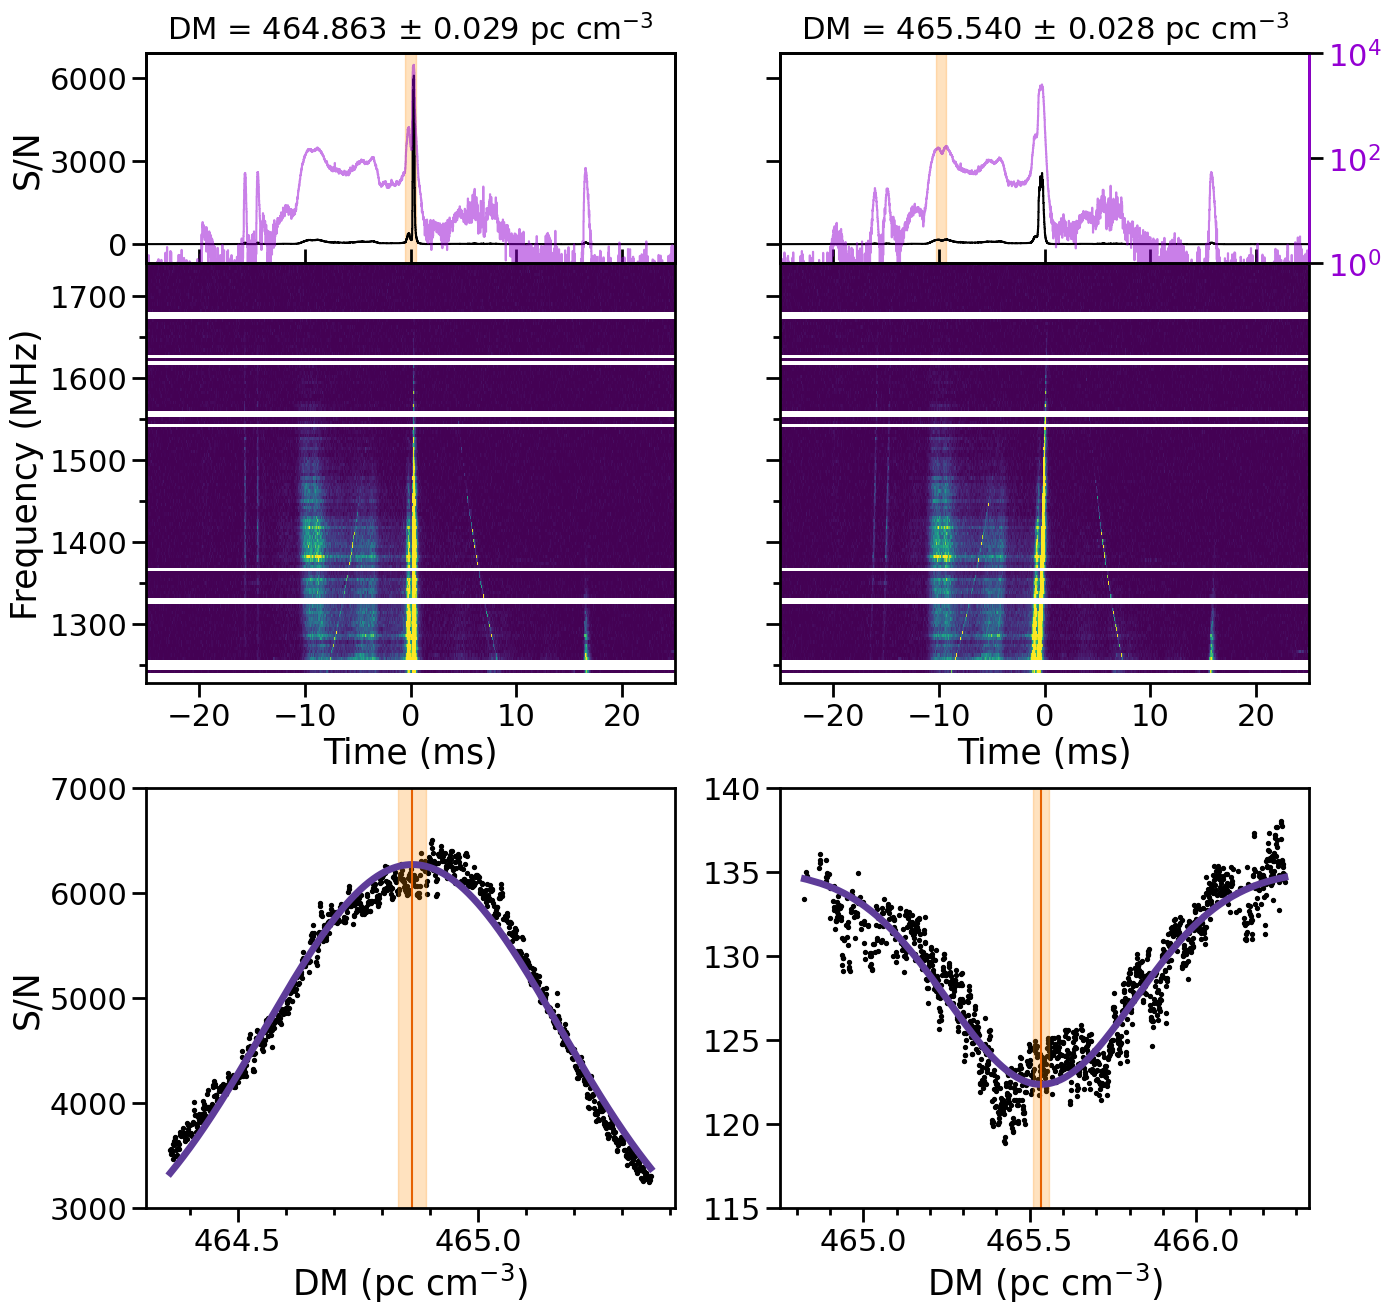

In [6]:
def waterfaller_dm():
    """
    ax1 ax2 -- time series
    ax3 ax4 -- dynamic spectra
    ax5 ax6 -- hspace plots -- these are invisible
    ax7 ax8 -- DM -- S/N plots
    
    ax5 and ax6 are there to give more space between the SN-DM plot and the dynamic spectrum
    
    Input:
    """
    ###################################
    #Loading in the burst
    burst_dat = "/scratch1/baseband_extractions/frb240619D_meerkat/nancay/burst_60511.98777606648s3p3t119.15.fil"
    
    #DM -- 464.863 
    stokes_i, stokes_i_normprof, x_grid, new_quantiles, extent = load_burst(DM=464.863, burst_name=burst_dat)

    #DM -- 465.534 
    stokes_i_sc, stokes_i_normprof_sc, x_grid_sc, new_quantiles_sc, extent_sc = load_burst(DM=465.534, burst_name=burst_dat)

    ###################################
    #Loading in the burst
    #Loading in the csv files
    df = pd.read_csv("NRT_DM_SN_1000_dmtrials.csv", sep=",", header=0, index_col=0)
    df_sc = pd.read_csv("NRT_DM_SN_subcomponent_minima_1500_dmtrials.csv", sep=",", header=0, index_col=0)
    
    ###################################
    #Define the figure
    fig5 = plt.figure(figsize=(15,15))
    
    #Width 0.1 is for the hidden axes
    widths = [1, 1]
    heights = [1, 2, 0.5, 2]
    spec5 = fig5.add_gridspec(ncols=2, nrows=4, width_ratios=widths, height_ratios=heights,\
                              wspace=0.2, hspace=0.0)

    #Making axis invisible
    ax5 = fig5.add_subplot(spec5[0, 1])
    ax6 = fig5.add_subplot(spec5[1, 1 ])
    ax5.set_visible(False)
    ax6.set_visible(False)

    ###################################
    #Drawing the dynamic spectra
    #ax3
    ax3 = fig5.add_subplot(spec5[1, 0])
    ax3.imshow(stokes_i, aspect='auto', interpolation='None', origin='lower',\
          extent=extent, vmin=new_quantiles[0], vmax=new_quantiles[1])
    window_ms = 25
    ax3.set_xlim(-window_ms,window_ms)
    ax3.set_ylabel('Frequency (MHz)',size=25)
    ax3.set_xlabel('Time (ms)',size=25)

    ax3.xaxis.set_minor_locator(ticker.MultipleLocator(10))
    majors = [1300,1400,1500,1600,1700]
    minors = [1250,1350,1450,1550,1650,1750]
    ax3.yaxis.set_major_locator(ticker.FixedLocator(majors))
    ax3.yaxis.set_minor_locator(ticker.FixedLocator(minors))
    
    #ax4
    ax4 = fig5.add_subplot(spec5[1, 1])
    ax4.set_xlabel('Time (ms)',size=25)
    ax4.imshow(stokes_i_sc, aspect='auto', interpolation='None', origin='lower',\
          extent=extent_sc, vmin=new_quantiles_sc[0], vmax=new_quantiles_sc[1])
    window_ms = 25
    ax4.set_xlim(-window_ms,window_ms)

    ax4.xaxis.set_minor_locator(ticker.MultipleLocator(10))
    majors = [1300,1400,1500,1600,1700]
    minors = [1250,1350,1450,1550,1650,1750]
    ax4.yaxis.set_major_locator(ticker.FixedLocator(majors))
    ax4.yaxis.set_minor_locator(ticker.FixedLocator(minors))

    ###################################
    #Drawing the time series
    #ax1
    ax1 = fig5.add_subplot(spec5[0, 0], sharex=ax3)
    ax1.set_ylabel('S/N',size=25)
    
    ax1.plot(x_grid, stokes_i_normprof, drawstyle='steps-post', color='black')
    xmin_v = -0.5
    xmax_v = 0.5
    ax1.axvspan(xmin=xmin_v, xmax=xmax_v, ymin=0, ymax=1, color='darkorange', alpha=0.25)    
    maxSN = np.ceil(np.max(stokes_i_normprof))
    yticks_sn=np.array([0, round(int(maxSN/2), -3), round(int(maxSN), -3)])
    ax1.set_yticks(yticks_sn)
    ax1.set_ylim(-700,maxSN+800)
    
    #log profile
    ax1_twin=ax1.twinx()
    ax1_twin.step(x_grid, stokes_i_normprof, drawstyle='steps-post', color='darkviolet', where='mid', alpha=0.5)
    ax1_twin.set_yscale('log')
    ax1_twin.set_ylim(1,1000_0)
    yticks_sn_log=np.array([])
    ax1_twin.set_yticks(yticks_sn_log)
    
    ax1.set_title(fr"DM = {464.863:.3f}" + " $\pm$ " + f"{0.029}" + r" pc cm$^{-3}$", fontsize=22, pad=10)

    #ax2
    ax2 = fig5.add_subplot(spec5[0, 1], sharex=ax4)
    ax2.plot(x_grid_sc, stokes_i_normprof_sc, drawstyle='steps-post', color='black')
    xmin_v = -10.3
    xmax_v = -9.35
    ax2.axvspan(xmin=xmin_v, xmax=xmax_v, ymin=0, ymax=1, color='darkorange', alpha=0.25)    
    ax2.set_yticks(yticks_sn)
    ax2.set_ylim(-700,maxSN+800)

    ax2_twin=ax2.twinx()
    ax2_twin.step(x_grid_sc, stokes_i_normprof_sc, drawstyle='steps-post', color='darkviolet', where='mid', alpha=0.5)
    ax2_twin.set_yscale('log')
    ax2_twin.set_ylim(1,1000_0)
    yticks_sn_log=np.array([10,100,1000,1000_0])
    #ax2.set_ylim(-700,maxSN_sc+800)
    ax2.set_title(fr"DM = {465.54:.3f}" + " $\pm$ " + f"{0.028}" + r" pc cm$^{-3}$", fontsize=22, pad=10)

    ###################################
    #Drawing S/N DM curves
    ax7 = fig5.add_subplot(spec5[3, 0])
    ax7.set_xlabel(r'DM (pc cm$^{-3})$',size=25)
    ax7.set_ylabel('S/N',size=25)

    sn_range = df["SN"].values
    dm_range = df["DM"].values 
    poptc,pcovc=curve_fit(gaus, dm_range, sn_range, p0=[0,464.87,0.1,5000], maxfev=10000)
    best_dm = poptc[1]
    sigma_3_err = 3*poptc[2]/np.sqrt(len(dm_range))

    #Plotting the whole range
    ax7.scatter(dm_range, sn_range,color='k',s=8)
    #Plotting only the gaussian
    dm_space = np.linspace(dm_range[0], dm_range[-1], 10000)
    ax7.plot(dm_range,gaus(dm_range,*poptc),color='#5e3c99',lw=5)
    ax7.axvline(best_dm,color="#e66101")
    ax7.axvspan(xmin=best_dm-sigma_3_err, xmax=best_dm+sigma_3_err, ymin=0, ymax=1, color='darkorange', alpha=0.25)
    ax7.set_ylim(3000,7000)
    ax7.xaxis.set_major_locator(ticker.MultipleLocator(0.5))
    ax7.xaxis.set_minor_locator(ticker.MultipleLocator(0.1))
    
    ax8 = fig5.add_subplot(spec5[3, 1])
    ax8.set_xlabel(r'DM (pc cm$^{-3})$',size=25)

    sn_filter = df_sc["SN"].values
    dm_filter = df_sc["DM"].values 
    # Create a mask to exclude NaN values
    mask = ~np.isnan(sn_filter)
    # Only keep the data points that are not NaN
    sn_range = sn_filter[mask]
    dm_range = dm_filter[mask]

    poptc,pcovc=curve_fit(flipped_gaus, dm_range, sn_range, p0=[0,465.5,0.1,180], maxfev=10000)
    best_dm = poptc[1]
    sigma_3_err = 3*poptc[2]/np.sqrt(len(dm_range))

    #Plotting the whole range
    ax8.scatter(dm_range, sn_range,color='k',s=8)
    #Plotting only the gaussian
    dm_space = np.linspace(dm_range[0], dm_range[-1], 10000)
    ax8.plot(dm_range,flipped_gaus(dm_range,*poptc),color='#5e3c99',lw=5)

    ax8.axvline(best_dm,color="#e66101")
    ax8.axvspan(xmin=best_dm-sigma_3_err, xmax=best_dm+sigma_3_err, ymin=0, ymax=1, color='darkorange', alpha=0.25)
    ax8.set_ylim(115,140)
    ax8.xaxis.set_major_locator(ticker.MultipleLocator(0.5))
    ax8.xaxis.set_minor_locator(ticker.MultipleLocator(0.1))
    
    
    ###################################
    #Settings for the plot

    for ax in [ax1,ax2,ax3,ax4,ax7,ax8,ax1_twin,ax2_twin]:
        
        ax.tick_params(labelsize=22) 
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
    
    for ax in [ax1, ax2]:
        
        ax.tick_params(labelbottom=False)
        ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)

    for ax in [ax2_twin]:
        ax.tick_params(labelcolor='darkviolet')
        ax.spines['right'].set_color('darkviolet')
        
    ax2.tick_params(labelleft=False)
    ax4.tick_params(labelleft=False)
    # ax8.tick_params(labelleft=False)

    ###################################
    #Saving the plot
    plot_name = "NRT_DM_optimization_V2"
    fig5.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
    
    fig5.savefig(plot_name + ".png", facecolor='white', \
            transparent=False, format = 'png',bbox_inches='tight', dpi=300)
    
    return

waterfaller_dm()